# 02 — Paradigma 1: detección supervisada en CISUTAC (bloque A)

**Pregunta:** al detectar agujeros y manchas pequeños en fotos de prendas usadas, ¿conviene reducir la foto completa, aumentar la resolución de entrada o recorrerla con *tiles* a resolución nativa? ¿Cuánto cuesta cada opción?

El EDA mostró que, al reducir la foto (2160×3840) a 640 px, la mediana del defecto queda en **4,2 px (agujeros) y 3,0 px (manchas)**, y que el baseline preliminar a 640 no encontró ningún defecto menor a 32 px. Este notebook arma el **baseline supervisado** y lo compara de forma controlada contra variantes que conservan más detalle.

| ID | Variante | Entrenamiento | Inferencia | Qué responde |
|---|---|---|---|---|
| **A0** | Foto completa 640 | foto reducida a lado mayor 640 | ídem | Baseline estándar de YOLO |
| **A1** | Más resolución | foto reducida a lado mayor 1280 (opcional 1920) | ídem | ¿Alcanza con subir `imgsz`? |
| **A2** | Tiles sólo en inferencia | modelo de A0 | tiles 640 a resolución nativa | Ablación: ¿importa que la escala de entrenamiento y la de inferencia coincidan? |
| **A3** | Tiles en entrenamiento e inferencia | tiles 640 (20 % solapamiento) | ídem, con y sin la foto completa | Hipótesis principal |
| **A3-abl** | Ablaciones de A3 | proporción de tiles sin defectos; tamaño de tile | — | Qué decisiones de diseño importan |

**Reglas del protocolo** (`reports/protocolo_experimental.md`):

- Mismo detector (**YOLO11n** preentrenado en COCO), misma semilla, mismos aumentos y el mismo **presupuesto de entrenamiento** medido en imágenes vistas.
- Todas las métricas se calculan **en coordenadas de la foto original**, con `src/detection_eval.py`: mAP@0.5, mAP@0.5:0.95, AP_small, recall por tamaño, tiempo por imagen.
- **Valid** elige épocas, umbrales y variantes. **Test se usa una sola vez**, al final, para A0 y la mejor variante.
- Holes y Spots se tratan por separado: el notebook corre un dataset por vez (`DATASET`).

> **Cómo correrlo.** Necesita los datos de CISUTAC (ver `docs/DATASETS.md`), `pip install ultralytics==8.4.209 sahi==0.14.0 pycocotools==2.0.11` y, en lo posible, GPU. Primero conviene correrlo con `MODO_PRUEBA = True` (1 época, pocas imágenes, unos minutos) para verificar que todo funciona. Cada entrenamiento y evaluación queda guardado en `results/cisutac/bloque_a/`: si se vuelve a ejecutar el notebook, **se reutilizan** y no se reentrena (salvo `REENTRENAR = True`).

> **Corrida con YOLO26n** (`MODELO = 'yolo26n.pt'`, lanzador `kaggle/kaggle_bloque_a_yolo26.ipynb`), dataset **Spots**. Sólo A0, A2 y A3; test sin evaluar. El análisis de los resultados está en las celdas **Lectura de…** después de cada tabla, en la sección 10 (conclusiones) y en la sección 11 (comparación con YOLO11n).

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import cisutac_baseline as cb
from detection_eval import SIZE_LABELS

pd.set_option("display.max_columns", 30)
print("Datos:", cb.DATA)
print("Resultados:", cb.RESULTS)

Datos: /tmp/rewear_data
Resultados: /kaggle/working/tp_final_vision/results/cisutac/bloque_a


## 0. Parámetros

Todos los parámetros que se prueban están en esta celda o al comienzo de cada sección, para que se vea qué cambia entre variantes.

In [2]:
DATASET = 'spots'  # fijado por el lanzador de Kaggle
MODO_PRUEBA = False  # fijado por el lanzador de Kaggle
REENTRENAR = False       # True: ignora corridas guardadas y vuelve a entrenar/evaluar
EVALUAR_TEST = False  # fijado por el lanzador de Kaggle

# Comunes a todas las variantes (el único cambio entre A0, A1 y A3 es cómo se procesa la escala)
MODELO = 'yolo26n.pt'  # fijado por el lanzador de Kaggle
SEMILLA = 0
EPOCAS_BASE = 100        # épocas para la foto completa; las demás variantes se igualan en imágenes vistas
PACIENCIA_BASE = 30      # épocas sin mejora en valid antes de cortar
CONF_EVAL = 0.001        # confianza mínima de las predicciones guardadas (bajo, para calcular mAP)

# Tiles: configuración principal (CIS-4: 97 % de los defectos entra entero en algún tile)
TILE, SOLAPAMIENTO = 640, 0.2
NEG_POR_POS = 0.0  # fijado por el lanzador de Kaggle
MIN_VISIBLE = 0.5        # fracción mínima de un defecto cortado para conservarlo como caja

if MODO_PRUEBA:
    EPOCAS_BASE, PACIENCIA_BASE = 1, 1
    FRACCION, LIMITE_EVAL, MAX_IMAGENES_TILES = 0.1, 3, 6
else:
    FRACCION, LIMITE_EVAL, MAX_IMAGENES_TILES = 1.0, None, None
SUFIJO = "_prueba" if MODO_PRUEBA else ""
BATCH = {640: 16, 1024: 8, 1280: 8, 1920: 4}   # se baja con la resolución para que entre en memoria

def nombre(variante):
    # Con otro modelo base, el nombre lo incluye; si no, train() reutilizaría en silencio las corridas de YOLO11n.
    modelo = "" if MODELO == "yolo11n.pt" else f"_{Path(MODELO).stem}"
    return f"{DATASET}_{variante}{modelo}{SUFIJO}"

def pesos(run_dir):
    return Path(run_dir) / "weights" / "best.pt"

def evaluar_valid(run_name, weights, modo, **kw):
    # Evalúa en valid con la foto completa o con tiles, y nombra la evaluación según la configuración.
    detalle = (f"completa{kw.get('imgsz', 640)}" if modo == "completa" else
               f"tiles{kw.get('tile', TILE)}_o{round(100 * kw.get('overlap', SOLAPAMIENTO))}"
               + ("+completa" if kw.get("also_full") else ""))
    return cb.evaluate(f"{run_name}__valid_{detalle}", DATASET, weights, split="valid", mode=modo,
                       conf=CONF_EVAL, limit=LIMITE_EVAL, reevaluate=REENTRENAR, **kw)

In [3]:
import importlib.metadata as md
for paquete in ("ultralytics", "sahi", "pycocotools", "torch"):
    try:
        print(f"{paquete:12s} {md.version(paquete)}")
    except md.PackageNotFoundError:
        print(f"{paquete:12s} FALTA -> pip install {paquete}")
print("Dispositivo:", cb.pick_device())

ultralytics  8.4.220
sahi         0.14.1
pycocotools  2.0.11
torch        2.11.0+cu130


Dispositivo: 0


## 1. Datos

Se usan sólo las **fotos originales** con el split CISUTAC v1 (agrupado por día, `reports/cisutac/cis5_split_propuesto.csv`). Si todavía no existe `data/derived/`, la celda siguiente corre `scripts/prepare_cisutac_yolo.py`, que arma enlaces/copias, labels YOLO y las cajas COCO de referencia sin tocar los originales.

In [4]:
if not (cb.derived_dir(DATASET) / "data.yaml").exists():
    subprocess.run([sys.executable, str(ROOT / "scripts" / "prepare_cisutac_yolo.py")], check=True)

gt = {split: cb.load_ground_truth(DATASET, split) for split in ("train", "valid", "test")}
pd.DataFrame({split: {"imágenes": len(g["images"]), "defectos": len(g["annotations"]),
                      "defectos por imagen": round(len(g["annotations"]) / len(g["images"]), 2)}
              for split, g in gt.items()}).T

,imágenes,defectos,defectos por imagen
train,361.0,1903.0,5.27
valid,59.0,284.0,4.81
test,66.0,311.0,4.71


Distribución de tamaños por split (lado equivalente √(ancho·alto) en px de la original). Los rangos se fijaron en el EDA, antes de entrenar. Interesa que train y valid tengan suficientes defectos chicos para poder medir la diferencia entre variantes.

In [5]:
from eda_utils import SIZE_EDGES

def rango(area):
    return SIZE_LABELS[sum(area ** 0.5 >= e for e in SIZE_EDGES)]

tamanos = pd.DataFrame({split: pd.Series([rango(a["area"]) for a in g["annotations"]]).value_counts()
                        for split, g in gt.items()}).reindex(SIZE_LABELS).fillna(0).astype(int)
tamanos.loc["COCO small (< 32 px)"] = [sum(a["area"] < 32 ** 2 for a in g["annotations"]) for g in gt.values()]
tamanos

,train,valid,test
< 8 px,403,72,71
8–16 px,451,66,69
16–32 px,408,61,67
32–64 px,303,34,48
≥ 64 px,338,51,56
COCO small (< 32 px),1262,199,207


**Por qué la escala importa.** Cada columna es un defecto chico real de valid: arriba a resolución nativa, abajo cómo queda cuando la foto completa se reduce a lado mayor 640 y 1280 (lo que recibe el modelo en A0 y A1).

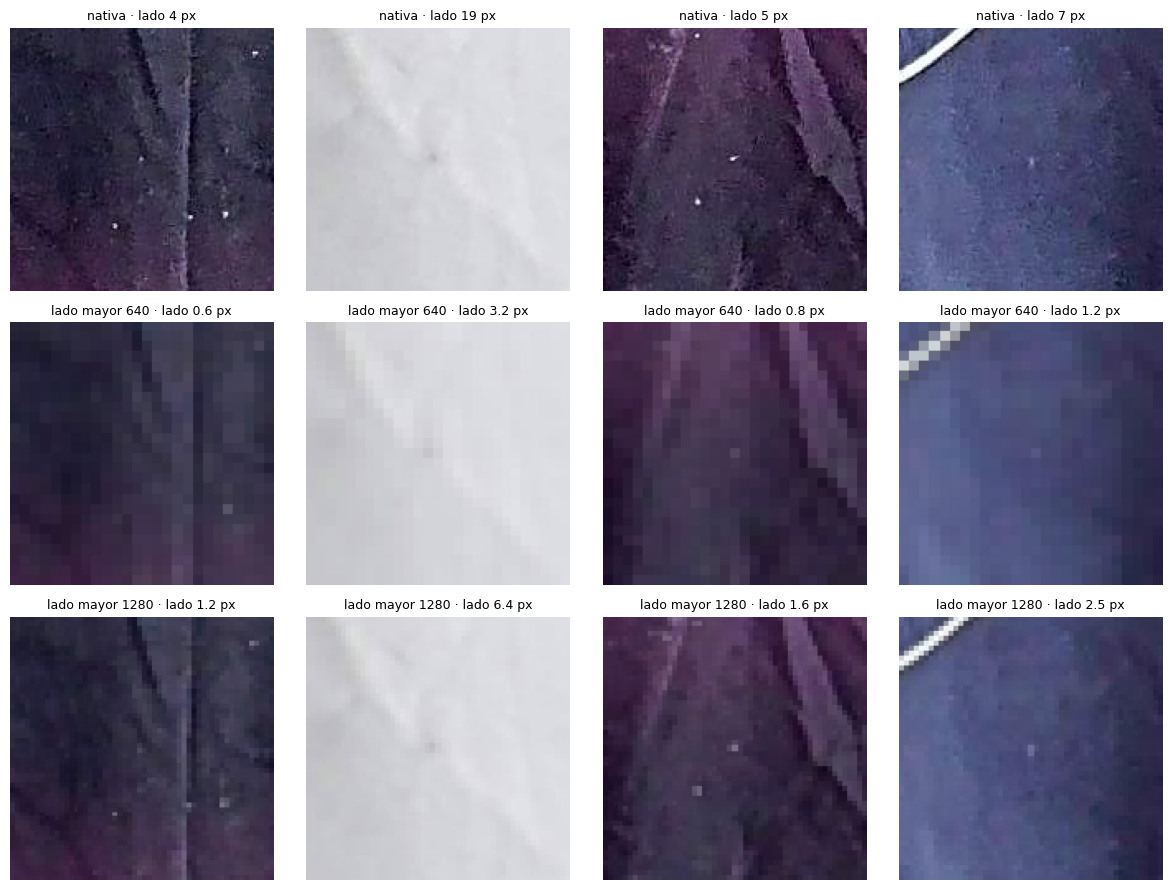

In [6]:
cb.plot_resolution_zoom(DATASET, sides=(640, 1280), n=4);

## 2. A0 — Baseline: foto completa a 640

YOLO11n preentrenado en COCO, ajustado con la foto completa reducida a lado mayor 640 (el `imgsz` por defecto de Ultralytics), con los aumentos por defecto (mosaico, escala ±50 %, giro horizontal, color). Valid sólo elige la mejor época.

Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/rewear_data/derived/cisutac_spots/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/tp_final_vision/results/pesos/yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=spots_A0_completa640_yolo26n, nbs=64, nms=None, opset=None, optimize=False, o

Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


... (1,563 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.3it/s 1.5s

                   all         59        284      0.088     0.0141     0.0142    0.00757


Speed: 0.2ms preprocess, 22.4ms inference, 0.0ms loss, 0.9ms postprocess per image


Results saved to /kaggle/working/tp_final_vision/results/cisutac/bloque_a/entrenamientos/spots_A0_completa640_yolo26n


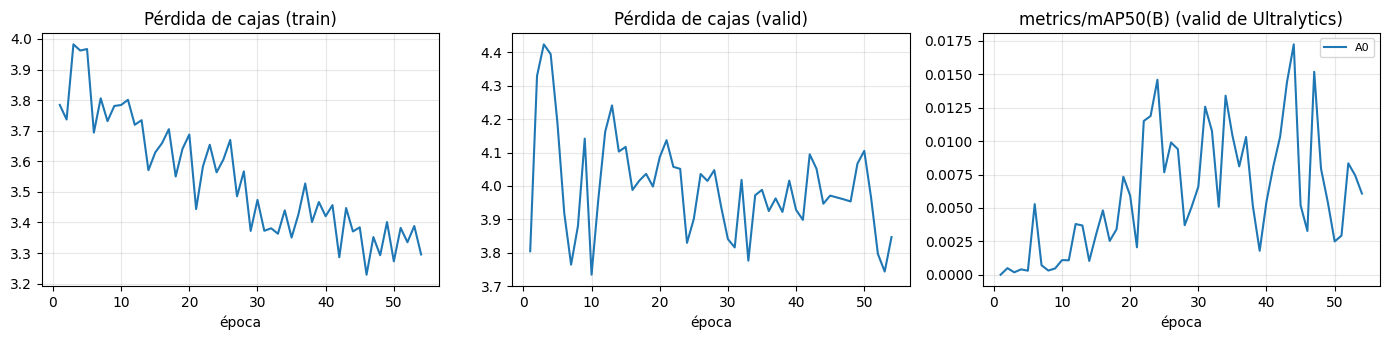

In [7]:
run_A0 = cb.train(nombre("A0_completa640"), cb.derived_dir(DATASET) / "data.yaml", imgsz=640,
                  epochs=EPOCAS_BASE, patience=PACIENCIA_BASE, batch=BATCH[640], seed=SEMILLA,
                  model=MODELO, retrain=REENTRENAR, fraction=FRACCION)
cb.plot_curves({"A0": run_A0});

Evaluación en valid, en coordenadas de la original. El umbral de confianza para precisión/recall/F1 es el que maximiza F1 en valid; mAP y AP_small no dependen de ese umbral.

In [8]:
eval_A0 = evaluar_valid(run_A0.name, pesos(run_A0), "completa", imgsz=640)
display(cb.metrics_table([eval_A0]))
display(cb.size_table([eval_A0]))

,modo,mAP@0.5,mAP@0.5:0.95,AP_small,AP_medium,AP_large,umbral_confianza,precision,recall,f1,segundos_por_imagen,tiles_por_imagen,recall (IC 95 %)
corrida,,,,,,,,,,,,,
spots_A0_completa640_yolo26n__valid_completa640,completa,0.006,0.003,0.0,0.017,0.002,0.04,0.107,0.021,0.035,0.037,1.0,0.021 (0.005–0.045)


,< 8 px,8–16 px,16–32 px,32–64 px,≥ 64 px
spots_A0_completa640_yolo26n__valid_completa640,0/72,0/66,0/61,2/34,4/51


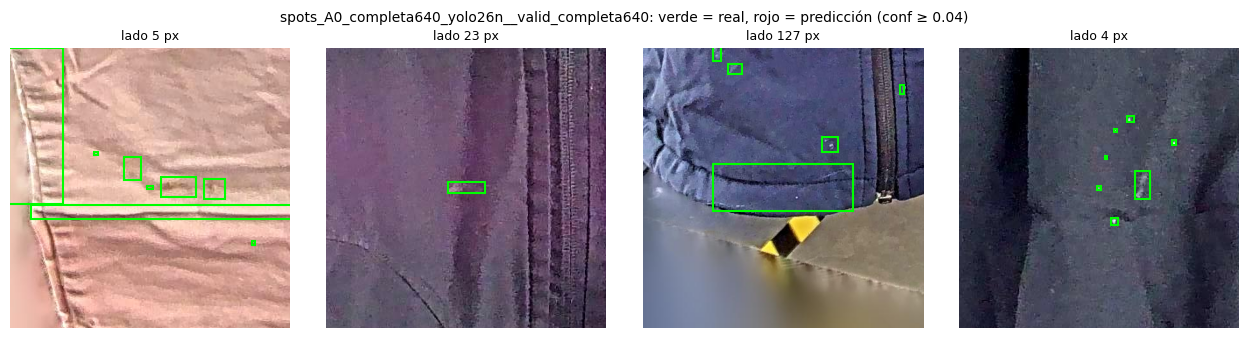

In [9]:
cb.plot_examples(DATASET, eval_A0["corrida"], n=4);

## 3. A1 — ¿Alcanza con subir la resolución de entrada?

Mismo modelo y receta, pero la foto completa entra con lado mayor más grande. Es el rival justo de los tiles: también procesa más píxeles, pero sin cortar la imagen. Se mantiene la misma cantidad de épocas que A0 (mismas imágenes vistas); el batch baja para que entre en memoria.

> 1920 necesita bastante memoria de GPU (≈ 9× los píxeles de 640). Agregarlo a la lista sólo si hay hardware.

,modo,mAP@0.5,mAP@0.5:0.95,AP_small,AP_medium,AP_large,umbral_confianza,precision,recall,f1,segundos_por_imagen,tiles_por_imagen,recall (IC 95 %)
corrida,,,,,,,,,,,,,
spots_A0_completa640_yolo26n__valid_completa640,completa,0.006,0.003,0.0,0.017,0.002,0.04,0.107,0.021,0.035,0.037,1.0,0.021 (0.005–0.045)


,< 8 px,8–16 px,16–32 px,32–64 px,≥ 64 px
spots_A0_completa640_yolo26n__valid_completa640,0/72,0/66,0/61,2/34,4/51


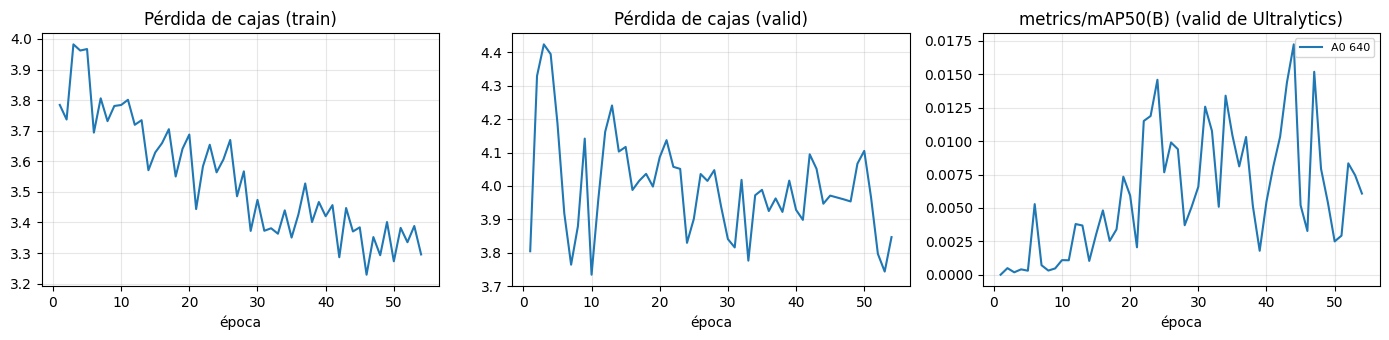

In [10]:
RESOLUCIONES_A1 = []  # fijado por el lanzador de Kaggle

runs_A1, evals_A1 = {}, []
for imgsz in RESOLUCIONES_A1:
    run = cb.train(nombre(f"A1_completa{imgsz}"), cb.derived_dir(DATASET) / "data.yaml", imgsz=imgsz,
                   epochs=EPOCAS_BASE, patience=PACIENCIA_BASE, batch=BATCH[imgsz], seed=SEMILLA,
                   model=MODELO, retrain=REENTRENAR, fraction=FRACCION)
    runs_A1[f"A1 {imgsz}"] = run
    evals_A1.append(evaluar_valid(run.name, pesos(run), "completa", imgsz=imgsz))

cb.plot_curves({"A0 640": run_A0, **runs_A1})
display(cb.metrics_table([eval_A0, *evals_A1]))
display(cb.size_table([eval_A0, *evals_A1]))

## 4. A2 — Tiles sólo en inferencia (ablación)

Se toma el modelo **ya entrenado en A0** y se lo aplica con tiles de 640 a resolución nativa (SAHI, fusión NMS a IoU 0,5), con y sin sumar la predicción de la foto completa. En el EDA esto **empeoró** el mAP: en los tiles los defectos se ven ~6 veces más grandes que en el entrenamiento. Se repite acá para que la comparación quede en la misma tabla.

In [11]:
evals_A2 = [evaluar_valid(run_A0.name, pesos(run_A0), "tiles", tile=TILE, overlap=SOLAPAMIENTO, also_full=full)
            for full in (False, True)]
display(cb.metrics_table([eval_A0, *evals_A2]))
display(cb.size_table([eval_A0, *evals_A2]))

2026-11-26 21:59:04,560 - sahi - WARNING - ignoring invalid prediction with bbox: [350.58782958984375, 585.5587158203125, 360.227783203125, 585.5145263671875] (ultralytics.py:285)


2026-11-26 21:59:48,668 - sahi - WARNING - ignoring invalid prediction with bbox: [350.58782958984375, 585.5587158203125, 360.227783203125, 585.5145263671875] (ultralytics.py:285)


,modo,mAP@0.5,mAP@0.5:0.95,AP_small,AP_medium,AP_large,umbral_confianza,precision,recall,f1,segundos_por_imagen,tiles_por_imagen,recall (IC 95 %)
corrida,,,,,,,,,,,,,
spots_A0_completa640_yolo26n__valid_completa640,completa,0.006,0.003,0.0,0.017,0.002,0.04,0.107,0.021,0.035,0.037,1.000,0.021 (0.005–0.045)
spots_A0_completa640_yolo26n__valid_tiles640_o20,tiles,0.002,0.000,0.0,0.007,0.000,0.16,0.020,0.025,0.022,0.573,31.186,0.025 (0.006–0.047)
spots_A0_completa640_yolo26n__valid_tiles640_o20+completa,tiles,0.002,0.001,0.0,0.021,0.000,0.18,0.029,0.028,0.029,0.655,32.186,0.028 (0.011–0.048)


,< 8 px,8–16 px,16–32 px,32–64 px,≥ 64 px
spots_A0_completa640_yolo26n__valid_completa640,0/72,0/66,0/61,2/34,4/51
spots_A0_completa640_yolo26n__valid_tiles640_o20,0/72,2/66,5/61,0/34,0/51
spots_A0_completa640_yolo26n__valid_tiles640_o20+completa,0/72,2/66,4/61,0/34,2/51


## 5. Dataset de tiles

Para entrenar a la misma escala con la que se infiere, cada foto de train y valid se recorre con la misma grilla que usa SAHI en inferencia. Cada tile se clasifica en:

- **con defecto:** contiene al menos un defecto que conserva `MIN_VISIBLE` (50 %) de su área. Las cajas cortadas se recortan al tile;
- **sin defecto:** no toca ningún defecto;
- **descartado:** sólo tiene fragmentos chicos de defectos cortados. Si se usaran como negativos, le enseñarían al modelo que medio agujero "no es defecto".

Como hay ~32 tiles por foto y la mayoría no tiene defectos, se toman `NEG_POR_POS` tiles sin defecto por cada tile con defecto (muestreo con semilla). Esa proporción es una decisión de diseño y se estudia en la sección 7.

**Presupuesto de entrenamiento.** El dataset de tiles tiene más imágenes que el de fotos completas, así que con las mismas épocas el modelo vería muchos más ejemplos. Para comparar en igualdad de condiciones se ajustan las épocas para ver aproximadamente la **misma cantidad de imágenes** que A0 (`cb.equivalent_epochs`).

In [12]:
yaml_tiles, stats_tiles = cb.build_tile_dataset(DATASET, tile=TILE, overlap=SOLAPAMIENTO, neg_per_pos=NEG_POR_POS,
                                                seed=SEMILLA, min_visible=MIN_VISIBLE, max_images=MAX_IMAGENES_TILES)
display(pd.DataFrame(stats_tiles).T)

n_completas = len(gt["train"]["images"]) if not MAX_IMAGENES_TILES else MAX_IMAGENES_TILES
def presupuesto(stats):
    # Épocas y paciencia equivalentes en imágenes vistas a EPOCAS_BASE sobre fotos completas.
    epocas = cb.equivalent_epochs(EPOCAS_BASE, n_completas, stats["train"]["tiles_totales"],
                                  minimum=1 if MODO_PRUEBA else 10)
    return epocas, max(1, round(PACIENCIA_BASE * epocas / EPOCAS_BASE))

EPOCAS_TILES, PACIENCIA_TILES = presupuesto(stats_tiles)
print(f"Épocas para tiles: {EPOCAS_TILES} (paciencia {PACIENCIA_TILES}) "
      f"≈ {EPOCAS_BASE} épocas × {n_completas} fotos completas")

,imagenes_originales,tiles_posibles,tiles_con_defecto,tiles_sin_defecto_disponibles,tiles_sin_defecto_usados,tiles_descartados_por_fragmentos,tiles_totales,cajas
train,361,11552,1253,10066,0,233,1253,3105
valid,59,1840,234,1564,0,42,234,487


Épocas para tiles: 29 (paciencia 9) ≈ 100 épocas × 361 fotos completas


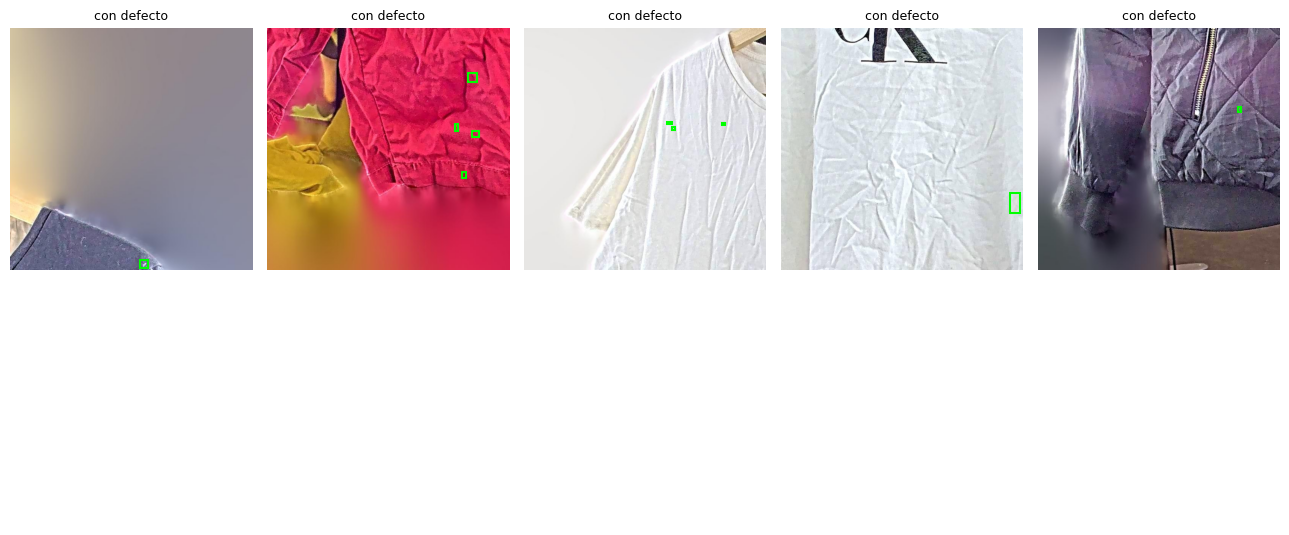

In [13]:
cb.plot_tile_samples(yaml_tiles, n=5);

## 6. A3 — Entrenar e inferir con tiles

Mismo YOLO11n, misma receta y presupuesto equivalente. En valid se infiere con SAHI sobre las **fotos originales completas** (no sobre los tiles), así que la evaluación es exactamente la misma que en A0–A2. Se prueba también sumar la predicción de la foto completa a 640, que en el EDA recuperaba defectos más grandes que un tile.

Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/rewear_data/derived/cisutac_spots_tiles/t640_o20/data_neg0_s0.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=29, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/tp_final_vision/results/pesos/yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=spots_A3_tiles640_neg0_yolo26n, nbs=64, nms=None, opset

Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


... (2,681 outputs left out)

Speed: 0.4ms preprocess, 5.6ms inference, 0.0ms loss, 1.5ms postprocess per image


Results saved to /kaggle/working/tp_final_vision/results/cisutac/bloque_a/entrenamientos/spots_A3_tiles640_neg0_yolo26n


,modo,mAP@0.5,mAP@0.5:0.95,AP_small,AP_medium,AP_large,umbral_confianza,precision,recall,f1,segundos_por_imagen,tiles_por_imagen,recall (IC 95 %)
corrida,,,,,,,,,,,,,
spots_A0_completa640_yolo26n__valid_completa640,completa,0.006,0.003,0.000,0.017,0.002,0.04,0.107,0.021,0.035,0.037,1.000,0.021 (0.005–0.045)
spots_A0_completa640_yolo26n__valid_tiles640_o20,tiles,0.002,0.000,0.000,0.007,0.000,0.16,0.020,0.025,0.022,0.573,31.186,0.025 (0.006–0.047)
spots_A0_completa640_yolo26n__valid_tiles640_o20+completa,tiles,0.002,0.001,0.000,0.021,0.000,0.18,0.029,0.028,0.029,0.655,32.186,0.028 (0.011–0.048)
spots_A3_tiles640_neg0_yolo26n__valid_tiles640_o20,tiles,0.036,0.012,0.016,0.013,0.007,0.12,0.150,0.137,0.143,0.499,31.186,0.137 (0.091–0.183)
spots_A3_tiles640_neg0_yolo26n__valid_tiles640_o20+completa,tiles,0.036,0.012,0.016,0.013,0.011,0.12,0.144,0.141,0.142,0.574,32.186,0.141 (0.093–0.188)


,< 8 px,8–16 px,16–32 px,32–64 px,≥ 64 px
spots_A0_completa640_yolo26n__valid_completa640,0/72,0/66,0/61,2/34,4/51
spots_A0_completa640_yolo26n__valid_tiles640_o20,0/72,2/66,5/61,0/34,0/51
spots_A0_completa640_yolo26n__valid_tiles640_o20+completa,0/72,2/66,4/61,0/34,2/51
spots_A3_tiles640_neg0_yolo26n__valid_tiles640_o20,8/72,12/66,8/61,5/34,6/51
spots_A3_tiles640_neg0_yolo26n__valid_tiles640_o20+completa,8/72,12/66,8/61,5/34,7/51


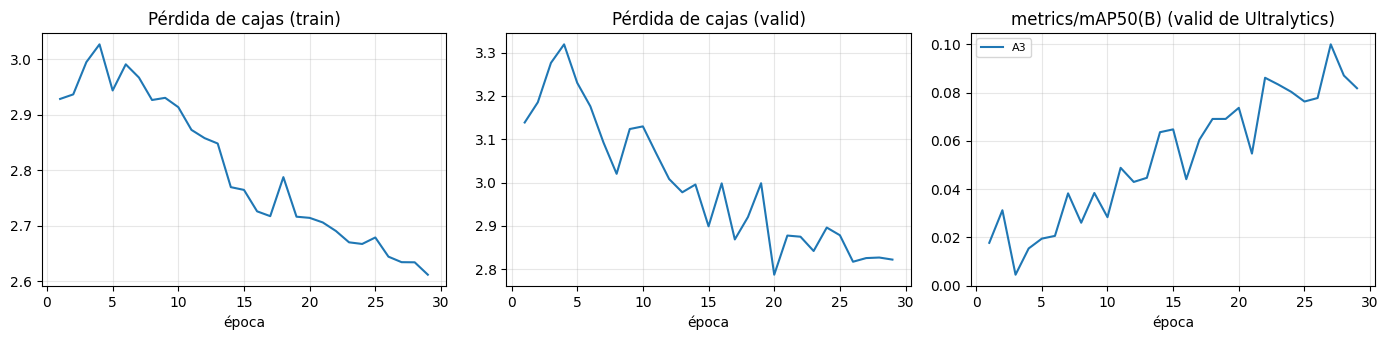

In [14]:
def entrenar_tiles(variante, data_yaml, stats, tile=TILE):
    epocas, paciencia = presupuesto(stats)
    return cb.train(nombre(variante), data_yaml, imgsz=tile, epochs=epocas, patience=paciencia,
                    batch=BATCH[tile], seed=SEMILLA, model=MODELO, retrain=REENTRENAR)

run_A3 = entrenar_tiles(f"A3_tiles{TILE}_neg{NEG_POR_POS:g}", yaml_tiles, stats_tiles)
cb.plot_curves({"A3": run_A3})

evals_A3 = [evaluar_valid(run_A3.name, pesos(run_A3), "tiles", tile=TILE, overlap=SOLAPAMIENTO, also_full=full)
            for full in (False, True)]
display(cb.metrics_table([eval_A0, *evals_A1, *evals_A2, *evals_A3]))
display(cb.size_table([eval_A0, *evals_A1, *evals_A2, *evals_A3]))

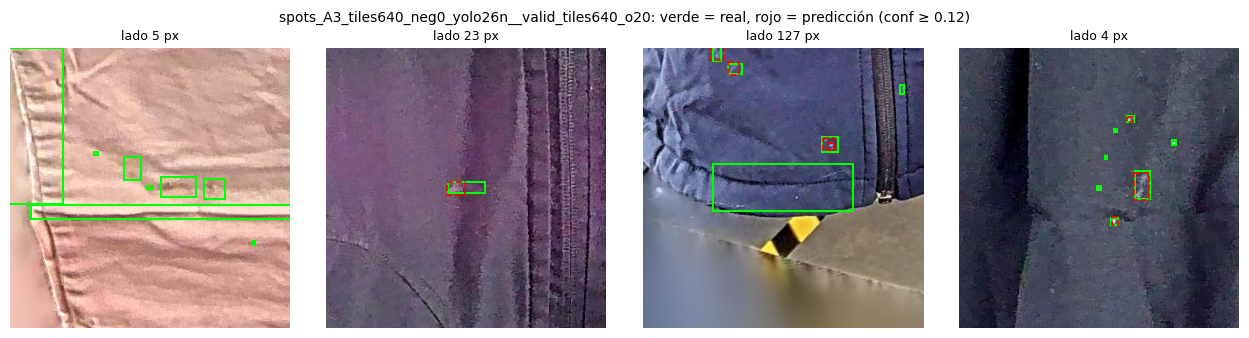

In [15]:
cb.plot_examples(DATASET, evals_A3[0]["corrida"], n=4);

## 7. Ablaciones de A3 (sólo en valid)

Se cambia **un factor por vez** a partir de la configuración principal de A3:

1. **Proporción de tiles sin defecto** (`NEG_POR_POS`). Con 0 el modelo nunca ve tela sana y se espera que confunda costuras, botones y estampados con defectos. Con muchos negativos aprende mejor el fondo, pero puede volverse conservador y perder recall.
2. **Tamaño de tile.** Tiles más chicos dan más contexto local y más pasadas (más costo); tiles más grandes, menos pasadas y más defectos enteros (CIS-4).

La inferencia usa siempre la grilla del mismo tamaño que el entrenamiento.

,modo,mAP@0.5,mAP@0.5:0.95,AP_small,AP_medium,AP_large,umbral_confianza,precision,recall,f1,segundos_por_imagen,tiles_por_imagen,recall (IC 95 %)
corrida,,,,,,,,,,,,,
spots_A3_tiles640_neg0_yolo26n__valid_tiles640_o20,tiles,0.036,0.012,0.016,0.013,0.007,0.12,0.15,0.137,0.143,0.499,31.186,0.137 (0.091–0.183)


,< 8 px,8–16 px,16–32 px,32–64 px,≥ 64 px
spots_A3_tiles640_neg0_yolo26n__valid_tiles640_o20,8/72,12/66,8/61,5/34,6/51


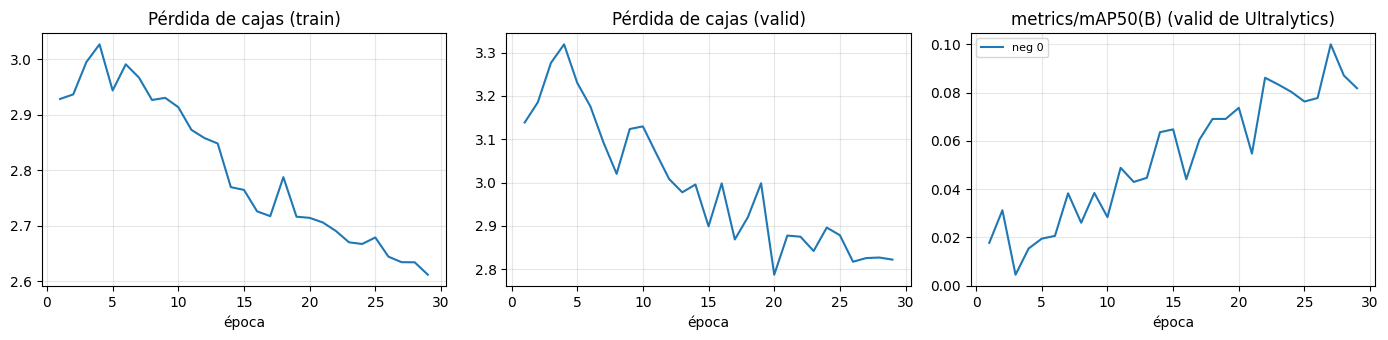

In [16]:
ABLACION_NEGATIVOS = []  # fijado por el lanzador de Kaggle

evals_neg, runs_neg = [], {}
for neg in ABLACION_NEGATIVOS:
    yaml_n, stats_n = cb.build_tile_dataset(DATASET, tile=TILE, overlap=SOLAPAMIENTO, neg_per_pos=neg, seed=SEMILLA,
                                            min_visible=MIN_VISIBLE, max_images=MAX_IMAGENES_TILES)
    run = entrenar_tiles(f"A3_tiles{TILE}_neg{neg:g}", yaml_n, stats_n)
    runs_neg[f"neg {neg:g}"] = run
    evals_neg.append(evaluar_valid(run.name, pesos(run), "tiles", tile=TILE, overlap=SOLAPAMIENTO))

cb.plot_curves({f"neg {NEG_POR_POS:g}": run_A3, **runs_neg})
display(cb.metrics_table([evals_A3[0], *evals_neg]))
display(cb.size_table([evals_A3[0], *evals_neg]))

In [17]:
ABLACION_TILES = []  # fijado por el lanzador de Kaggle

evals_tile = []
for tile in ABLACION_TILES:
    yaml_t, stats_t = cb.build_tile_dataset(DATASET, tile=tile, overlap=SOLAPAMIENTO, neg_per_pos=NEG_POR_POS,
                                            seed=SEMILLA, min_visible=MIN_VISIBLE, max_images=MAX_IMAGENES_TILES)
    run = entrenar_tiles(f"A3_tiles{tile}_neg{NEG_POR_POS:g}", yaml_t, stats_t, tile=tile)
    evals_tile.append(evaluar_valid(run.name, pesos(run), "tiles", tile=tile, overlap=SOLAPAMIENTO))

display(cb.metrics_table([evals_A3[0], *evals_tile]))
display(cb.size_table([evals_A3[0], *evals_tile]))

,modo,mAP@0.5,mAP@0.5:0.95,AP_small,AP_medium,AP_large,umbral_confianza,precision,recall,f1,segundos_por_imagen,tiles_por_imagen,recall (IC 95 %)
corrida,,,,,,,,,,,,,
spots_A3_tiles640_neg0_yolo26n__valid_tiles640_o20,tiles,0.036,0.012,0.016,0.013,0.007,0.12,0.15,0.137,0.143,0.499,31.186,0.137 (0.091–0.183)


,< 8 px,8–16 px,16–32 px,32–64 px,≥ 64 px
spots_A3_tiles640_neg0_yolo26n__valid_tiles640_o20,8/72,12/66,8/61,5/34,6/51


## 8. Comparación de todas las variantes en valid

La tabla junta todas las evaluaciones de valid de este dataset que existan en `results/` (también las de corridas anteriores). Los gráficos muestran dónde ayuda cada variante: el recall por tamaño responde directamente la hipótesis (¿mejoran los defectos < 32 px?) y el gráfico de costo muestra a qué precio.

In [18]:
todas = [json.loads(p.read_text()) for p in sorted((cb.RESULTS / "evaluaciones").glob(f"{DATASET}_*__valid_*/metricas.json"))]
todas = [m for m in todas if ("_prueba" in m["corrida"]) == MODO_PRUEBA]  # no mezclar pruebas con corridas reales
tabla_valid = cb.metrics_table(todas).sort_values("mAP@0.5", ascending=False)
tabla_valid

,modo,mAP@0.5,mAP@0.5:0.95,AP_small,AP_medium,AP_large,umbral_confianza,precision,recall,f1,segundos_por_imagen,tiles_por_imagen,recall (IC 95 %)
corrida,,,,,,,,,,,,,
spots_A3_tiles640_neg0_yolo26n__valid_tiles640_o20+completa,tiles,0.036,0.012,0.016,0.013,0.011,0.12,0.144,0.141,0.142,0.574,32.186,0.141 (0.093–0.188)
spots_A3_tiles640_neg0_yolo26n__valid_tiles640_o20,tiles,0.036,0.012,0.016,0.013,0.007,0.12,0.150,0.137,0.143,0.499,31.186,0.137 (0.091–0.183)
spots_A0_completa640_yolo26n__valid_completa640,completa,0.006,0.003,0.000,0.017,0.002,0.04,0.107,0.021,0.035,0.037,1.000,0.021 (0.005–0.045)
spots_A0_completa640_yolo26n__valid_tiles640_o20+completa,tiles,0.002,0.001,0.000,0.021,0.000,0.18,0.029,0.028,0.029,0.655,32.186,0.028 (0.011–0.048)
spots_A0_completa640_yolo26n__valid_tiles640_o20,tiles,0.002,0.000,0.000,0.007,0.000,0.16,0.020,0.025,0.022,0.573,31.186,0.025 (0.006–0.047)


,< 8 px,8–16 px,16–32 px,32–64 px,≥ 64 px
spots_A0_completa640_yolo26n__valid_completa640,0/72,0/66,0/61,2/34,4/51
spots_A0_completa640_yolo26n__valid_tiles640_o20,0/72,2/66,5/61,0/34,0/51
spots_A0_completa640_yolo26n__valid_tiles640_o20+completa,0/72,2/66,4/61,0/34,2/51
spots_A3_tiles640_neg0_yolo26n__valid_tiles640_o20,8/72,12/66,8/61,5/34,6/51
spots_A3_tiles640_neg0_yolo26n__valid_tiles640_o20+completa,8/72,12/66,8/61,5/34,7/51


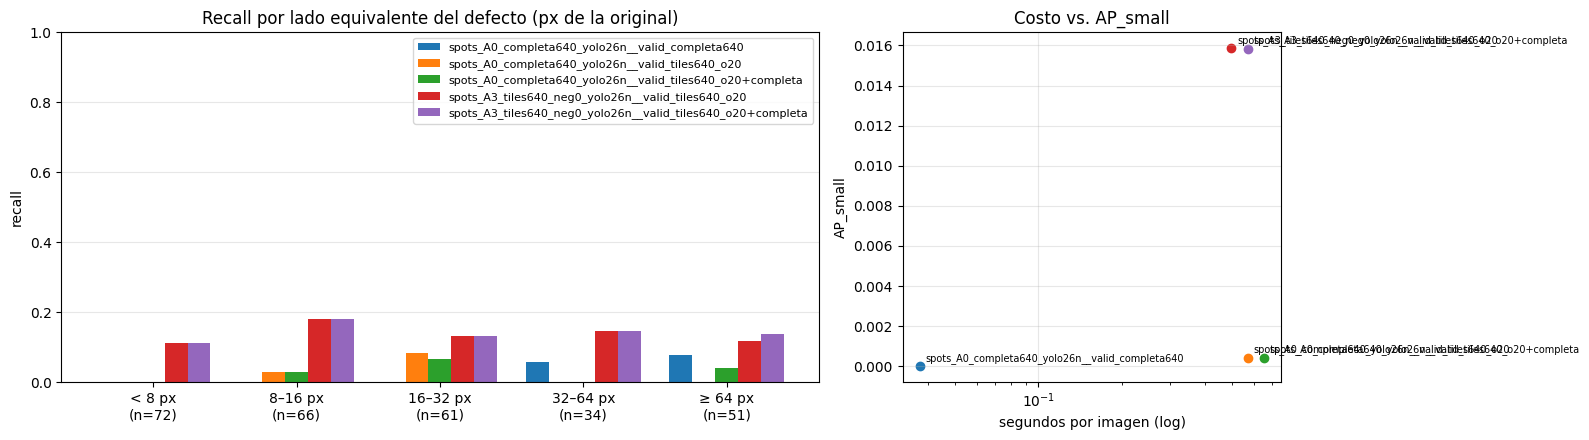

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [2, 1]})
cb.plot_recall_by_size(todas, ax=axes[0])
cb.plot_cost_vs_quality(todas, metric="AP_small", ax=axes[1])
plt.tight_layout()
display(cb.size_table(todas))

**Lectura de la tabla (Spots, YOLO26n).**

- **A3 (tiles de 640, sin negativos) vuelve a ser la mejor variante,** pero el nivel es muy bajo: mAP@0.5 = **0.036**, contra 0.006 de A0. Recall 0.137 y precisión 0.150.
- **A2 (el modelo de A0 aplicado con tiles) no sirve:** 0.002, con 96 % de alucinaciones. Es el mismo motivo que en Holes: el modelo no fue entrenado a esa escala.
- **`+completa` no cambia nada** (0.036 contra 0.036).
- No se corrieron A1 ni ablaciones con YOLO26.

### ¿Por qué el mAP es bajo? Análisis de errores (sólo valid)

Con el umbral de confianza elegido en valid de cada corrida y en coordenadas de la original, `scripts/analyze_detection_errors.py` (con las funciones de `src/detection_eval.py`) clasifica:

- cada **predicción** como acierto (IoU ≥ 0,5), **error de localización** (IoU entre 0,1 y 0,5 con un defecto real: lo encontró pero encuadró mal), **duplicado** (otra predicción sobre un defecto ya detectado) o **alucinación** (IoU < 0,1 con todos los defectos);
- cada **defecto real**, por tamaño, como detectado, encontrado sólo con caja mala o **no detectado**.

También mide el recall a IoU 0,1, 0,3 y 0,5 (cuánto se recupera si se perdona el encuadre) y cuánto subiría mAP@0.5 si se corrigiera cada tipo de error, como TIDE (Bolya et al., ECCV 2020). Para ver recortes de cada tipo de error: `python scripts/plot_cisutac_predictions.py --dataset holes --por-error --corrida <carpeta de la evaluación> --salida ejemplos.jpg`.

,umbral,predicciones,pct_aciertos,pct_localizacion,pct_duplicados,pct_alucinaciones
corrida,,,,,,
spots_A0_completa640_yolo26n__valid_completa640,0.04,56,0.107,0.161,0.0,0.732
spots_A0_completa640_yolo26n__valid_tiles640_o20,0.16,343,0.020,0.020,0.0,0.959
spots_A0_completa640_yolo26n__valid_tiles640_o20+completa,0.18,275,0.029,0.029,0.0,0.942
spots_A3_tiles640_neg0_yolo26n__valid_tiles640_o20,0.12,260,0.150,0.142,0.0,0.708
spots_A3_tiles640_neg0_yolo26n__valid_tiles640_o20+completa,0.12,278,0.144,0.140,0.0,0.716


defectos  \
corrida                                            rango                
spots_A0_completa640_yolo26n__valid_completa640    < 16 px        138   
                                                   16–32 px        61   
                                                   ≥ 32 px         85   
                                                   total          284   
spots_A0_completa640_yolo26n__valid_tiles640_o20   < 16 px        138   
                                                   16–32 px        61   
                                                   ≥ 32 px         85   
                                                   total          284   
spots_A0_completa640_yolo26n__valid_tiles640_o2... < 16 px        138   
                                                   16–32 px        61   
                                                   ≥ 32 px         85   
                                                   total          284   
spots_A3_tiles640_neg0_yolo26n__valid_tiles640_o20 < 16 px        138   
                                                   16–32 px        61   
                                                   ≥ 32 px         85   
                                                   total          284   
spots_A3_tiles640_neg0_yolo26n__valid_tiles640_... < 16 px        138   
                                                   16–32 px        61   
                                                   ≥ 32 px         85   
                                                   total          284   

                                                             detectados  \
corrida                                            rango                  
spots_A0_completa640_yolo26n__valid_completa640    < 16 px            0   
                                                   16–32 px           0   
                                                   ≥ 32 px            6   
                                                   total              6   
spots_A0_completa640_yolo26n__valid_tiles640_o20   < 16 px            2   
                                                   16–32 px           5   
                                                   ≥ 32 px            0   
                                                   total              7   
spots_A0_completa640_yolo26n__valid_tiles640_o2... < 16 px            2   
                                                   16–32 px           4   
                                                   ≥ 32 px            2   
                                                   total              8   
spots_A3_tiles640_neg0_yolo26n__valid_tiles640_o20 < 16 px           20   
                                                   16–32 px           8   
                                                   ≥ 32 px           11   
                                                   total             39   
spots_A3_tiles640_neg0_yolo26n__valid_tiles640_... < 16 px           20   
                                                   16–32 px           8   
                                                   ≥ 32 px           12   
                                                   total             40   

                                                             caja_mala  \
corrida                                            rango                 
spots_A0_completa640_yolo26n__valid_completa640    < 16 px           0   
                                                   16–32 px          0   
                                                   ≥ 32 px           5   
                                                   total             5   
spots_A0_completa640_yolo26n__valid_tiles640_o20   < 16 px           3   
                                                   16–32 px          0   
                                                   ≥ 32 px           4   
                                                   total             7   
spots_A0_completa640_yolo26n__valid_tiles640_o2... < 16 px     

,mAP@0.5,delta_localizacion,delta_duplicados,delta_alucinaciones,delta_no_detectados
corrida,,,,,
spots_A0_completa640_yolo26n__valid_completa640,0.006,0.021,0.0,0.011,0.013
spots_A0_completa640_yolo26n__valid_tiles640_o20,0.002,0.004,0.0,0.040,0.005
spots_A0_completa640_yolo26n__valid_tiles640_o20+completa,0.002,0.006,0.0,0.043,0.005
spots_A3_tiles640_neg0_yolo26n__valid_tiles640_o20,0.036,0.048,0.0,0.096,0.029
spots_A3_tiles640_neg0_yolo26n__valid_tiles640_o20+completa,0.036,0.046,0.0,0.095,0.030


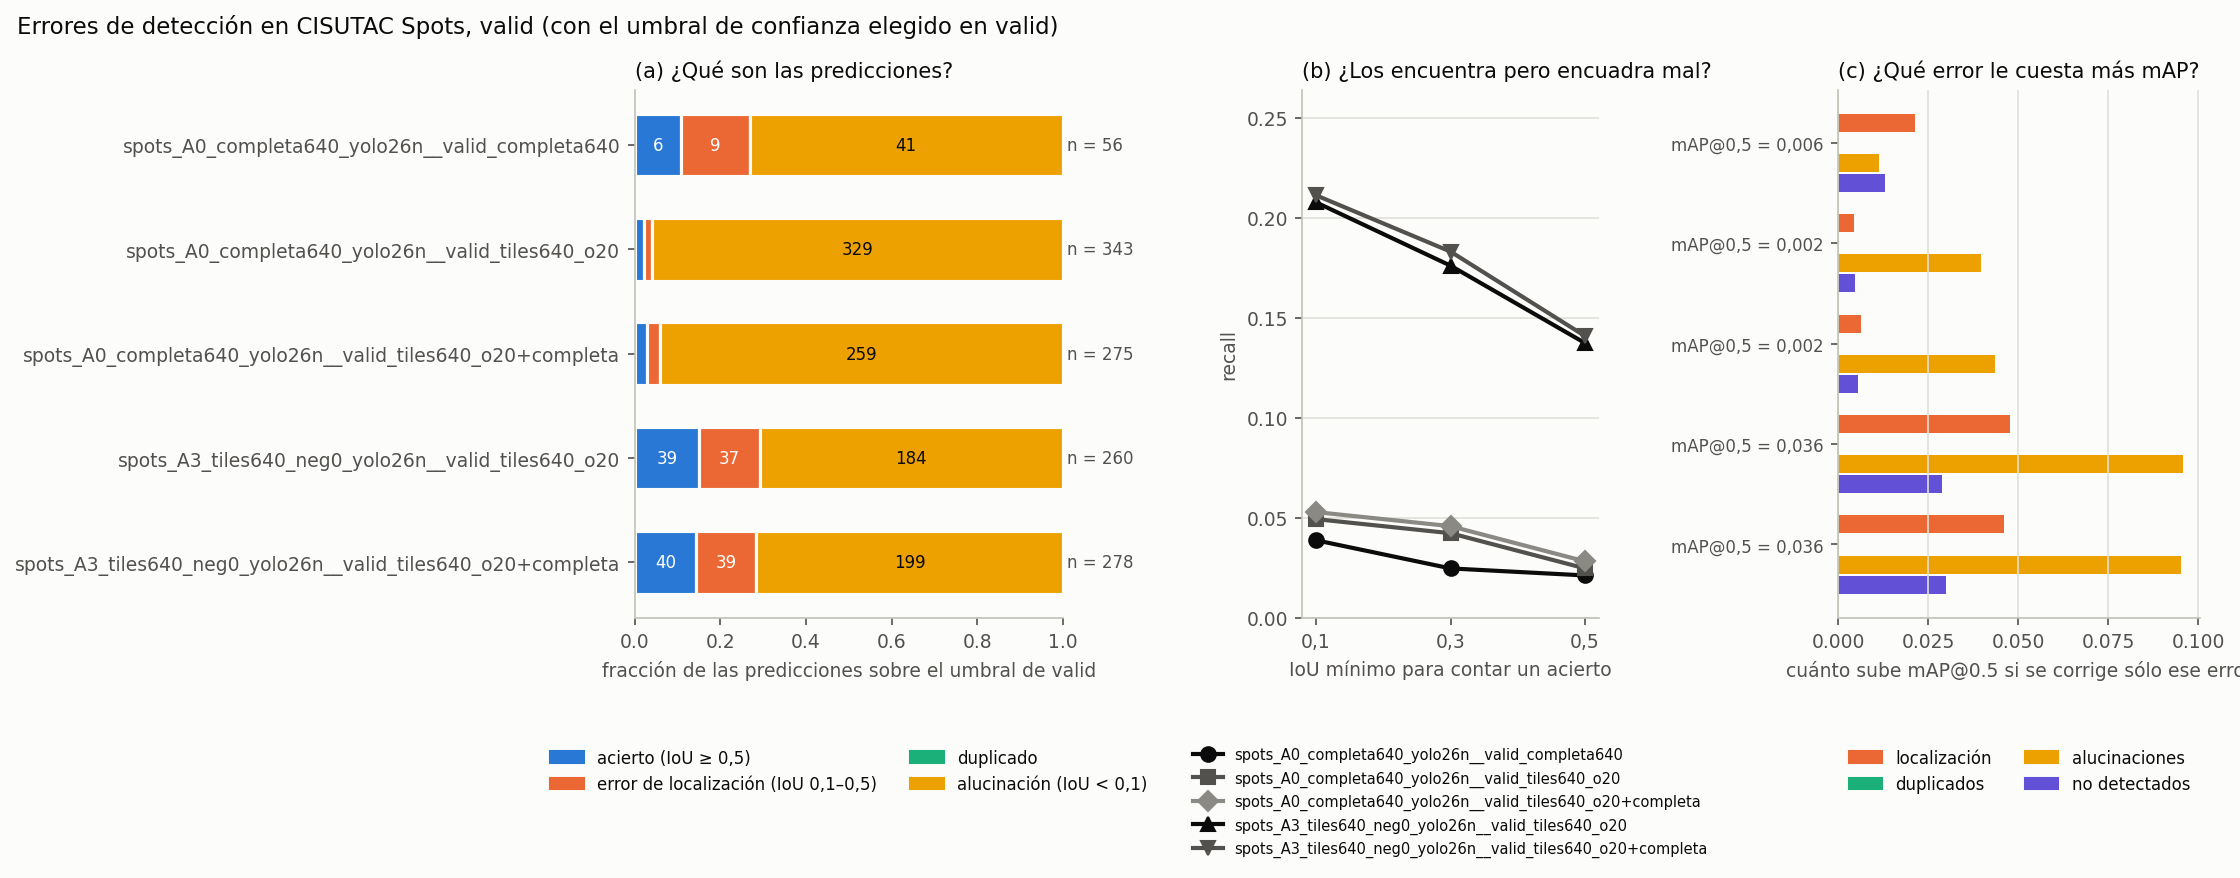

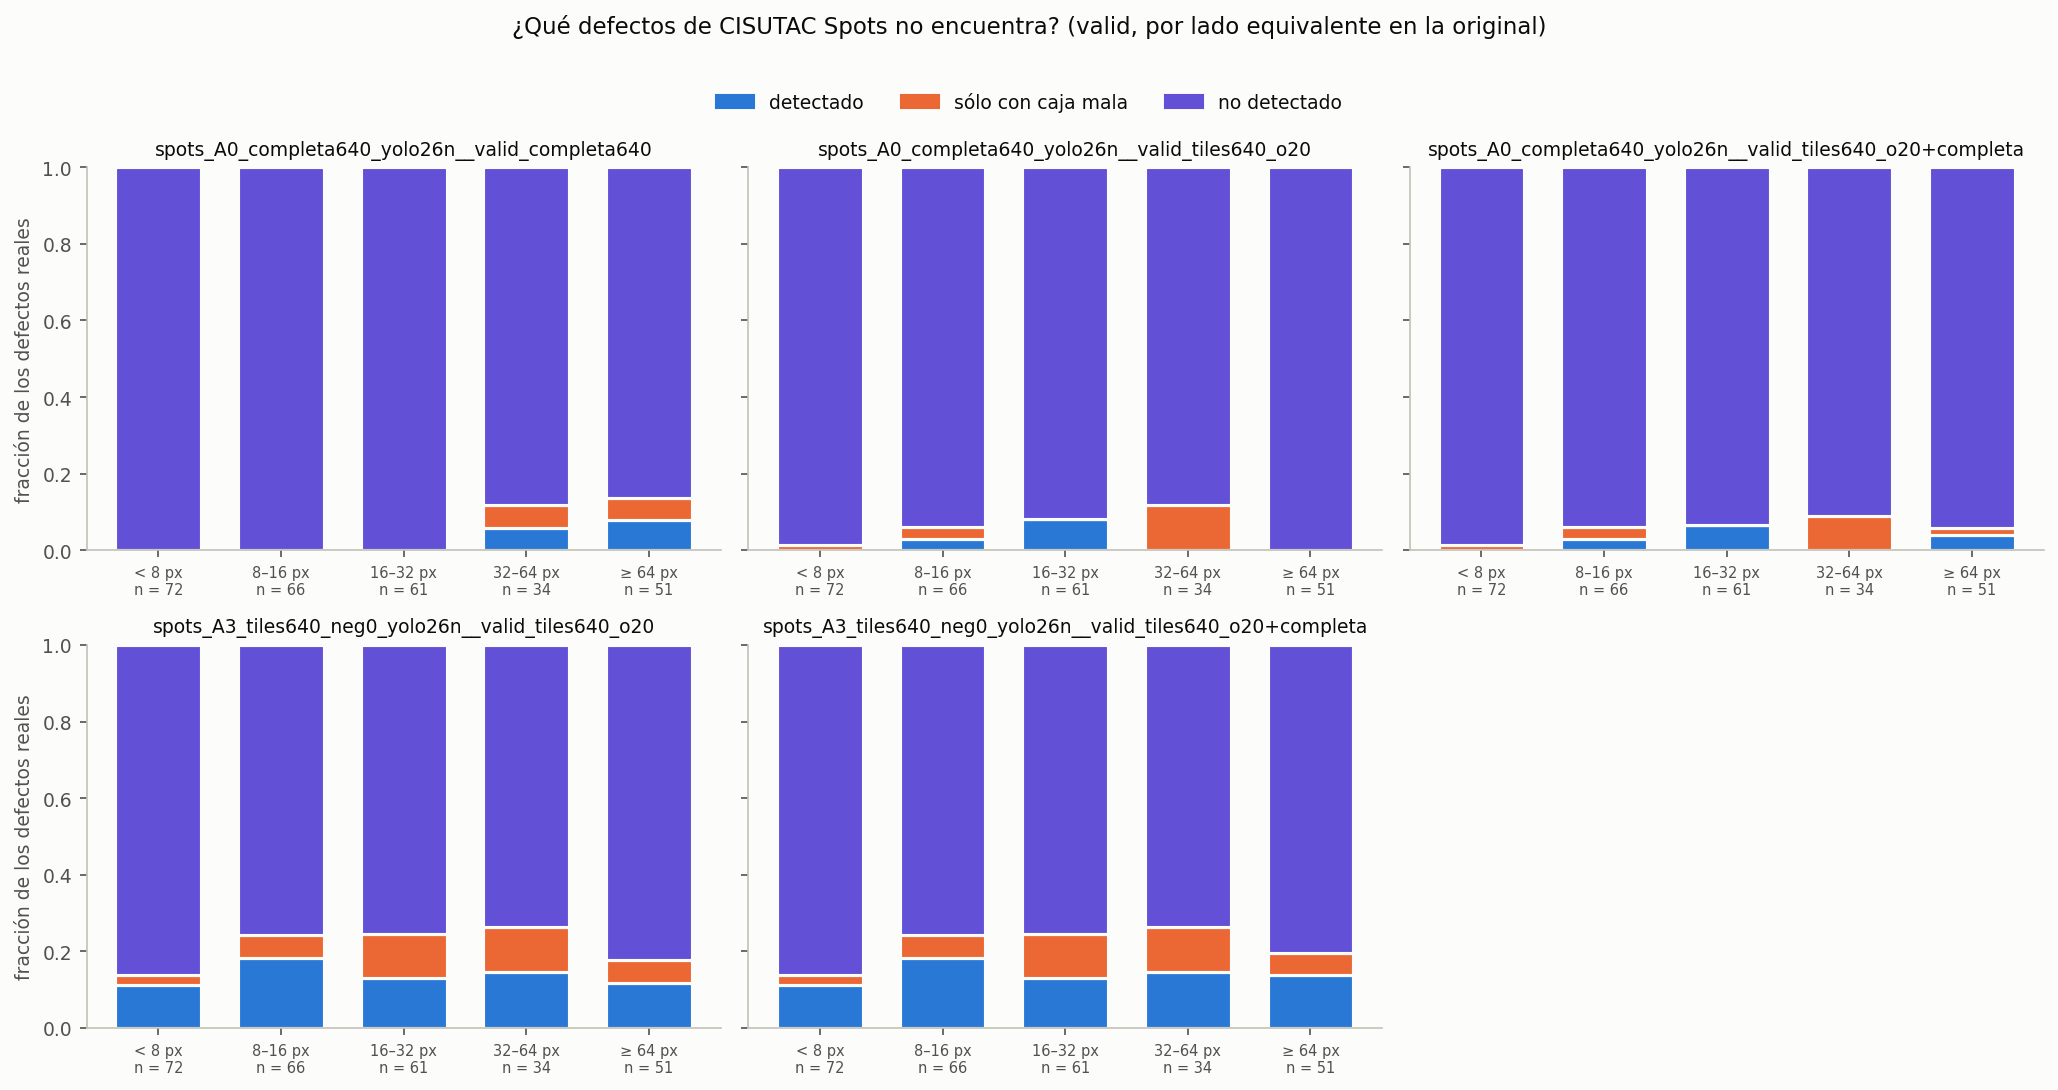

In [20]:
sys.path.insert(0, str(ROOT / "scripts"))
import analyze_detection_errors as ade
from IPython.display import Image

corridas = [ade.load_run(cb.RESULTS / "evaluaciones" / m["corrida"]) for m in todas]
analisis = [a for a in (ade.analyze(r) for r in corridas if r) if a]
filas_pred, filas_def, filas_delta = ade.table_rows(analisis)
display(pd.DataFrame(filas_pred).set_index("corrida")[["umbral", "predicciones", "pct_aciertos", "pct_localizacion",
                                                       "pct_duplicados", "pct_alucinaciones"]].round(3))
display(pd.DataFrame(filas_def).set_index(["corrida", "rango"])[["defectos", "detectados", "caja_mala", "no_detectados",
                                                                 "recall_iou0.1", "recall_iou0.3", "recall_iou0.5"]].round(3))
display(pd.DataFrame(filas_delta).set_index("corrida").drop(columns="dataset").round(3))

carpeta_errores = cb.RESULTS / "analisis_errores" / f"{DATASET}{SUFIJO}"
carpeta_errores.mkdir(parents=True, exist_ok=True)
ade.plot_summary(analisis, carpeta_errores / "errores.png")
ade.plot_by_size(analisis, carpeta_errores / "errores_por_tamano.png")
display(Image(filename=str(carpeta_errores / "errores.png")),
        Image(filename=str(carpeta_errores / "errores_por_tamano.png")))

**Lectura del análisis de errores (Spots, YOLO26n, A3).** Con el umbral elegido en valid (0.12), el modelo hace 260 predicciones:

| | Cantidad | % |
|---|---|---|
| Aciertos (IoU ≥ 0.5) | 39 | 15.0 % |
| Error de localización (IoU 0.1–0.5) | 37 | 14.2 % |
| Duplicados | 0 | 0 % |
| Alucinaciones (IoU < 0.1) | 184 | 70.8 % |

- **El modelo alucina mucho y además no encuentra la mayoría:** 7 de cada 10 predicciones no tocan ninguna mancha anotada, y **225 de las 284 manchas de valid (79 %) no se detectan**. Corregir las alucinaciones sumaría +0.096 de mAP y el encuadre +0.048.
- **El recall es parejo entre tamaños** (14.5 % en < 16 px, 13 % en 16–32 px y en ≥ 32 px). A diferencia de Holes, el tamaño no explica el problema.
- **Hipótesis principal: la anotación, no el modelo.** En Spots hay cajas grandes que agrupan varias manchas (por ejemplo, una caja de 626 px sobre un grupo) mientras que el modelo marca cada mancha por separado: esas predicciones cuentan como alucinaciones o errores de localización aunque estén sobre una mancha real. Además, "mancha" es una clase mucho más ambigua visualmente que "agujero" (sombras, estampados, cambios de color de la tela).

## 9. Selección en valid y evaluación única en test

**Criterio fijado antes de mirar test:** se elige la variante con tiles de mayor **mAP@0.5 en valid** (métrica principal del protocolo); en caso de empate se prefiere la más barata. En test se evalúan sólo el baseline A0 y esa variante, cada una con **su umbral de confianza elegido en valid**.

Con un test de 64 (Holes) y 66 (Spots) fotos, si los intervalos de confianza se superponen **no se puede afirmar una mejora**.

In [21]:
con_tiles = [m for m in todas if m["modo"] == "tiles" and "A3_" in m["corrida"]]
mejor = max(con_tiles, key=lambda m: (m["mAP@0.5"], -m["segundos_por_imagen"])) if con_tiles else None
print("Baseline :", eval_A0["corrida"])
print("Elegida  :", mejor and mejor["corrida"])

if EVALUAR_TEST and mejor:
    finales = []
    for m in (eval_A0, mejor):
        finales.append(cb.evaluate(m["corrida"].replace("__valid_", "__test_"), DATASET, m["pesos"], split="test",
                                   mode=m["modo"], imgsz=m["imgsz"], tile=m["tile"], overlap=m["solapamiento"],
                                   also_full=m["tambien_completa"], conf=CONF_EVAL, threshold=m["umbral_confianza"],
                                   confirm_test=True))
    display(cb.metrics_table(finales))
    display(cb.size_table(finales))
    cb.plot_recall_by_size(finales)
else:
    print("Test no evaluado (EVALUAR_TEST = False).")

Baseline : spots_A0_completa640_yolo26n__valid_completa640
Elegida  : spots_A3_tiles640_neg0_yolo26n__valid_tiles640_o20
Test no evaluado (EVALUAR_TEST = False).


## 10. Conclusiones (Spots, YOLO26n)

- **Escala:** A3 vuelve a ser la mejor variante (0.036 contra 0.006 de A0), y A2 vuelve a no servir. Pero el nivel absoluto es muy bajo.
- **Modelo:** YOLO26n da lo mismo que YOLO11n (0.039 → 0.036). El techo no es la arquitectura.
- **Errores que quedan:** 71 % de las predicciones son alucinaciones y 79 % de las manchas no se detectan, sin que el tamaño explique la diferencia.
- **Hipótesis:** la anotación agrupa varias manchas en una caja y la clase es visualmente ambigua; con una métrica por caja estricta (IoU 0.5), el modelo queda penalizado aunque marque manchas reales.
- **Limitaciones:** una semilla, valid de 59 fotos, test sin evaluar, sin A1 ni ablaciones con YOLO26.
- **Próximo paso:** medir con IoU 0.1 o por imagen (¿la prenda tiene manchas o no?), revisar ejemplos de alucinaciones para ver cuántas son manchas reales sin anotar, y considerar un modelo único Holes + Spots o el enfoque de anomalías.

## 11. Comparación con YOLO11n (mismo protocolo, sólo valid)

Mismo split, misma receta de tiles y misma evaluación en coordenadas de la original; sólo cambia el modelo preentrenado (`yolo11n.pt` → `yolo26n.pt`). Los números de YOLO11n salen de `notebooks/ejecutados/02_ejecutado_spots.ipynb` y de su análisis de errores.

| | YOLO11n | YOLO26n |
|---|---|---|
| mAP@0.5 A0 (foto completa 640) | 0.011 | 0.006 |
| **mAP@0.5 A3 (tiles)** | 0.039 | 0.036 |
| Precisión A3 | 0.137 | 0.150 |
| Recall A3 (IoU 0.5) | 0.130 | 0.137 |
| Recall A3 (IoU 0.1) | 0.211 | 0.208 |
| Predicciones A3 | 271 | 260 |
| Aciertos | 37 | 39 |
| Errores de localización | 41 | 37 |
| Alucinaciones | 191 | 184 |
| Defectos nunca detectados | 224 | 225 |
| Δ mAP si se corrige el encuadre | +0.053 | +0.048 |
| Δ mAP si se eliminan las alucinaciones | +0.093 | +0.096 |

- **En Spots YOLO26 no cambia nada:** 0.039 → 0.036. Diferencia con bootstrap pareado por imágenes de valid (1000 remuestreos): -0.003 (IC 95 % [-0.019, +0.013], P(dif > 0) = 0.36). Aciertos, alucinaciones y no detectados son prácticamente iguales.
- **Que dos arquitecturas distintas den el mismo resultado indica que el techo lo pone el dataset, no el modelo:** la granularidad de las cajas (grupos de manchas en una sola caja) y la ambigüedad visual de la clase. Cambiar de detector no va a resolverlo; habría que revisar la anotación (por ejemplo, evaluar con IoU 0.1 o por imagen) o cambiar de paradigma.
- **Holes contra Spots:** la misma receta (tiles + YOLO26) mejora mucho un tipo de defecto y nada el otro. Los agujeros tienen forma y borde definidos (son un objeto); las manchas no.